## RANDOM FOREST TRAINING

**Mục tiêu:** minh họa quá trình xây dựng rừng cây, thời gian huấn luyện, cấu trúc mô hình và lưu mô hình.

In [ ]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import joblib, time
ROOT = Path.cwd().resolve()
if ROOT.name == 'notebooks':
    ROOT = ROOT.parent
DATA = ROOT / 'data' / 'processed'
REPORTS = ROOT / 'reports' / '04_random_forest_training'
RESULTS = ROOT / 'models'
(REPORTS / 'figures').mkdir(parents=True, exist_ok=True)
(REPORTS / 'tables').mkdir(parents=True, exist_ok=True)
RESULTS.mkdir(parents=True, exist_ok=True)
TARGET = 'Attack_type'


### 1. Nạp dữ liệu Train và kiểm tra đầu vào

In [ ]:
df = pd.read_csv(DATA / 'rf_train.csv')
assert TARGET in df and df.isna().sum().sum() == 0
X = df.drop(columns=[TARGET]).to_numpy(dtype=np.float32)
y = df[TARGET].to_numpy(dtype=np.int64)
assert np.isfinite(X).all()
print('Train:', X.shape, '| classes:', np.unique(y).tolist())

Train: (82536, 92) | classes: [0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11]


### 2. Khai báo mô hình
Sử dụng **120 cây**, `criterion=gini`, `bootstrap=True`, `max_features=sqrt`, `class_weight=balanced_subsample`, `random_state=42`. `warm_start=True` cho phép bổ sung cây theo từng đợt. Mỗi đợt bổ sung 20 cây và giữ nguyên các cây trước đó.

In [ ]:
from sklearn.ensemble import RandomForestClassifier
model = RandomForestClassifier(n_estimators=20, criterion='gini', bootstrap=True,
    max_features='sqrt', min_samples_leaf=1, class_weight='balanced_subsample',
    random_state=42, n_jobs=-1, warm_start=True)
print(model)

RandomForestClassifier(class_weight='balanced_subsample', n_estimators=20,
                       n_jobs=-1, random_state=42, warm_start=True)


### 3. Huấn luyện có log tiến độ
Thời gian là thời gian thực đo trên môi trường đang chạy. Số cây tăng từ 20 đến 120.

In [ ]:
history=[]
total_start=time.perf_counter()
for trees in range(20,121,20):
    model.set_params(n_estimators=trees)
    start=time.perf_counter()
    model.fit(X,y)
    elapsed=time.perf_counter()-start
    history.append({'trees_built':len(model.estimators_),'batch_seconds':elapsed,'total_seconds':time.perf_counter()-total_start})
    print(f"Built {len(model.estimators_):3d}/120 trees | batch {elapsed:.2f}s | total {history[-1]['total_seconds']:.2f}s",flush=True)
train_seconds=time.perf_counter()-total_start
hist=pd.DataFrame(history)
hist.to_csv(REPORTS/'tables'/'rf_training_progress.csv',index=False)
print('FINISHED RF TRAINING:',round(train_seconds,2),'seconds')

c:\Program Data\Anaconda3\Lib\site-packages\sklearn\ensemble\_forest.py:860: UserWarning: class_weight presets "balanced" or "balanced_subsample" are not recommended for warm_start if the fitted data differs from the full dataset. In order to use "balanced" weights, use compute_class_weight ("balanced", classes, y). In place of y you can use a large enough sample of the full training set target to properly estimate the class frequency distributions. Pass the resulting weights as the class_weight parameter.
  warn(


Built  20/120 trees | batch 1.57s | total 1.57s


c:\Program Data\Anaconda3\Lib\site-packages\sklearn\ensemble\_forest.py:860: UserWarning: class_weight presets "balanced" or "balanced_subsample" are not recommended for warm_start if the fitted data differs from the full dataset. In order to use "balanced" weights, use compute_class_weight ("balanced", classes, y). In place of y you can use a large enough sample of the full training set target to properly estimate the class frequency distributions. Pass the resulting weights as the class_weight parameter.
  warn(


Built  40/120 trees | batch 2.00s | total 3.57s


c:\Program Data\Anaconda3\Lib\site-packages\sklearn\ensemble\_forest.py:860: UserWarning: class_weight presets "balanced" or "balanced_subsample" are not recommended for warm_start if the fitted data differs from the full dataset. In order to use "balanced" weights, use compute_class_weight ("balanced", classes, y). In place of y you can use a large enough sample of the full training set target to properly estimate the class frequency distributions. Pass the resulting weights as the class_weight parameter.
  warn(


Built  60/120 trees | batch 1.40s | total 4.97s


... (2 outputs left out)

c:\Program Data\Anaconda3\Lib\site-packages\sklearn\ensemble\_forest.py:860: UserWarning: class_weight presets "balanced" or "balanced_subsample" are not recommended for warm_start if the fitted data differs from the full dataset. In order to use "balanced" weights, use compute_class_weight ("balanced", classes, y). In place of y you can use a large enough sample of the full training set target to properly estimate the class frequency distributions. Pass the resulting weights as the class_weight parameter.
  warn(


Built 100/120 trees | batch 1.36s | total 7.74s


c:\Program Data\Anaconda3\Lib\site-packages\sklearn\ensemble\_forest.py:860: UserWarning: class_weight presets "balanced" or "balanced_subsample" are not recommended for warm_start if the fitted data differs from the full dataset. In order to use "balanced" weights, use compute_class_weight ("balanced", classes, y). In place of y you can use a large enough sample of the full training set target to properly estimate the class frequency distributions. Pass the resulting weights as the class_weight parameter.
  warn(


Built 120/120 trees | batch 1.61s | total 9.35s
FINISHED RF TRAINING: 9.36 seconds


### 4. Kiểm tra cấu trúc mô hình và trực quan tiến độ
Độ sâu/số nút mô tả độ phức tạp cây.

Trees: 120 | Depth min/mean/max: 14 21.62 28
Nodes min/mean/max: 479 588.5 729


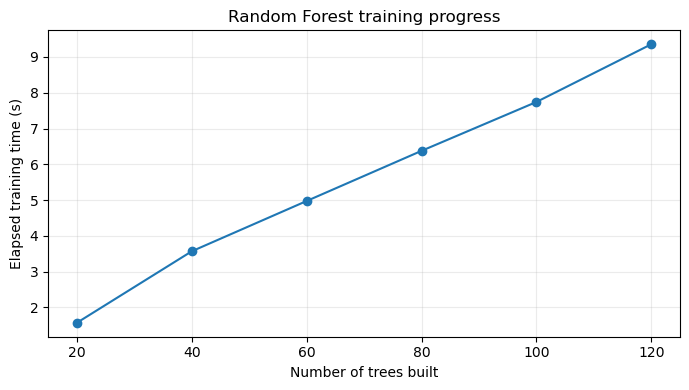

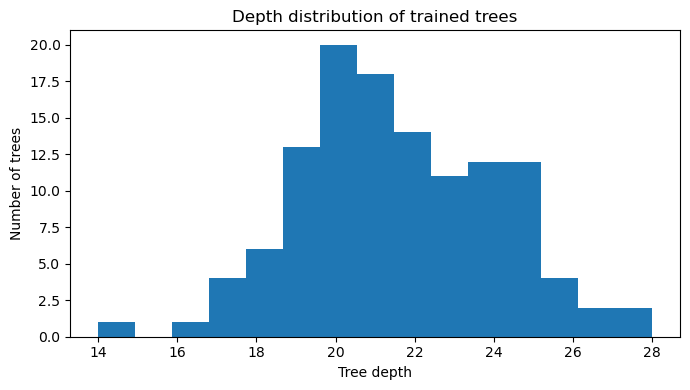

In [ ]:
depths=np.array([t.tree_.max_depth for t in model.estimators_]); nodes=np.array([t.tree_.node_count for t in model.estimators_])
print('Trees:',len(model.estimators_),'| Depth min/mean/max:',depths.min(),round(depths.mean(),2),depths.max())
print('Nodes min/mean/max:',nodes.min(),round(nodes.mean(),2),nodes.max())
fig,ax=plt.subplots(figsize=(7,4));ax.plot(hist.trees_built,hist.total_seconds,marker='o');ax.set(xlabel='Number of trees built',ylabel='Elapsed training time (s)',title='Random Forest training progress');ax.grid(alpha=.25);fig.tight_layout();fig.savefig(REPORTS/'figures'/'rf_training_progress.png',dpi=160);plt.show()
fig,ax=plt.subplots(figsize=(7,4));ax.hist(depths,bins=15);ax.set(xlabel='Tree depth',ylabel='Number of trees',title='Depth distribution of trained trees');fig.tight_layout();fig.savefig(REPORTS/'figures'/'rf_tree_depths.png',dpi=160);plt.show()

### 5. Lưu và nạp lại mô hình
Kiểm tra tính tái sử dụng của mô hình.

In [ ]:
path=RESULTS/'rf_baseline.joblib';joblib.dump(model,path)
reloaded=joblib.load(path)
assert np.array_equal(model.predict(X[:10]),reloaded.predict(X[:10]))
print('PASS: model reloaded; file:',path,'| bytes:',path.stat().st_size)

PASS: model reloaded; file: C:\homework\Machine Learning\SGU26K2_MayHoc_DCT124C3_Nhom4_RT-IoT2022\ĐỒ ÁN CUỐI KỲ NHÓM 4\models\rf_baseline.joblib | bytes: 11356409
